In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/customers_clean.csv")
pipeline = joblib.load("../models/customeriq_kmeans_pipeline.joblib")

FEATURES = ["Number_of_Orders", "Avg_Order_Value", "Days_Since_Last_Purchase",
            "Items_Per_Order", "Average_Rating", "Discount_Applied"]
df["Cluster"] = pipeline.predict(df[FEATURES])
df["Cluster"].value_counts().sort_index()


Cluster
0    13726
1    20911
2    11834
3    13529
Name: count, dtype: int64

In [2]:
money = df.groupby("Cluster").agg(customers=("Cluster", "size"),
                                  revenue=("Total_Spend", "sum"))
money["pct_of_customers"] = (money["customers"] / money["customers"].sum() * 100).round(1)
money["pct_of_revenue"] = (money["revenue"] / money["revenue"].sum() * 100).round(1)
money[["customers", "pct_of_customers", "pct_of_revenue"]]

,customers,pct_of_customers,pct_of_revenue
Cluster,,,
0,13726,22.9,2.0
1,20911,34.9,19.2
2,11834,19.7,63.2
3,13529,22.5,15.6


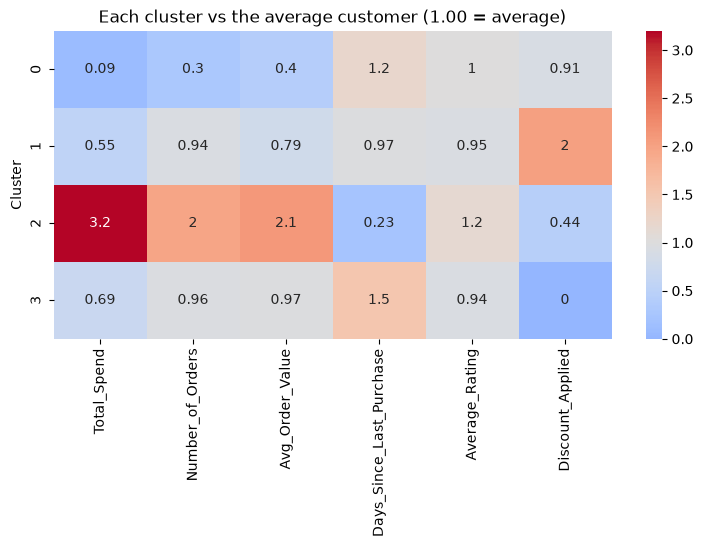

In [3]:
cols = ["Total_Spend", "Number_of_Orders", "Avg_Order_Value",
        "Days_Since_Last_Purchase", "Average_Rating", "Discount_Applied"]
relative = df.groupby("Cluster")[cols].mean() / df[cols].mean()

plt.figure(figsize=(9, 4))
sns.heatmap(relative.round(2), annot=True, cmap="coolwarm", center=1)
plt.title("Each cluster vs the average customer (1.00 = average)")
plt.show()

In [4]:
print(pd.crosstab(df["Cluster"], df["Gender"], normalize="index").round(2), "\n")
print(pd.crosstab(df["Cluster"], df["Satisfaction_Level"], normalize="index").round(2))

Gender   Female  Male  Other
Cluster                     
0          0.48  0.49   0.03
1          0.48  0.49   0.03
2          0.49  0.48   0.03
3          0.48  0.49   0.03 

Satisfaction_Level  High   Low  Medium
Cluster                               
0                   0.34  0.18    0.48
1                   0.25  0.26    0.49
2                   0.71  0.03    0.26
3                   0.25  0.27    0.48
